In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os 

In [2]:
train=pd.read_csv("../data/raw/train.csv",low_memory=False)
test=pd.read_csv("../data/raw/test.csv",low_memory=False)
store=pd.read_csv("../data/raw/store.csv",low_memory=False)

In [3]:
print("Train",train.shape)
print("test",test.shape)
print("store",store.shape)

Train (1017209, 9)
test (41088, 8)
store (1115, 10)


In [4]:
print("Train Columns : ")
print(train.columns.tolist())
print("\nTest columns : ")
print(test.columns.tolist())
print("\nStore columns : ")
print(store.columns.tolist())


Train Columns : 
['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']

Test columns : 
['Id', 'Store', 'DayOfWeek', 'Date', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']

Store columns : 
['Store', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']


In [5]:
train.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  object
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(2)
memory usage: 69.8+ MB


In [7]:
train.isnull().sum()

Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

In [8]:
train.duplicated().sum()

np.int64(0)

In [9]:
train['Date']=pd.to_datetime(train['Date'])

In [10]:
train['Date'].dtype

dtype('<M8[ns]')

In [11]:
print("Start date : ",train['Date'].min())

Start date :  2013-01-01 00:00:00


In [12]:
print("End Date : ",train['Date'].max())

End Date :  2015-07-31 00:00:00


In [13]:
train['Sales'].describe()

count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64

Text(0, 0.5, 'Frequency')

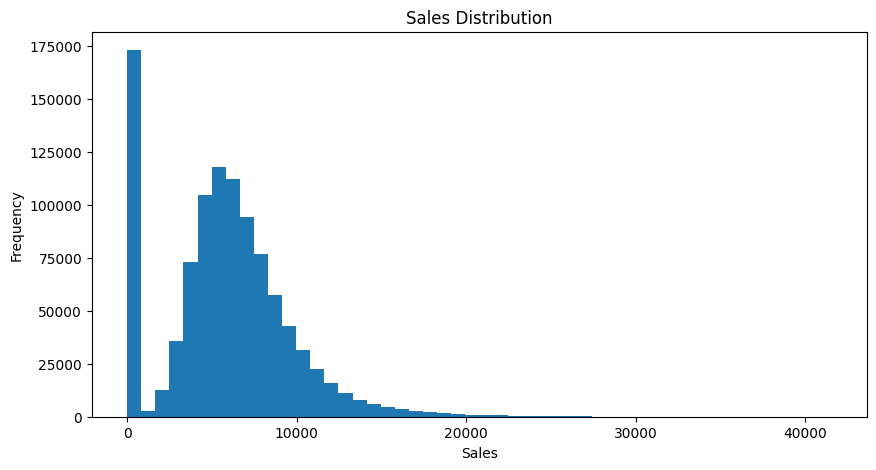

In [14]:
plt.figure(figsize=(10,5))

plt.hist(train['Sales'],bins=50)

plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")

In [15]:
train[train['Sales'] == 0].shape[0]

172871

In [16]:
train[train['Sales']==0]['Open'].value_counts()

Open
0    172817
1        54
Name: count, dtype: int64

In [17]:
train['Open'].value_counts()

Open
1    844392
0    172817
Name: count, dtype: int64

In [18]:
train[(train['Sales'] == 0) & (train['Open'] == 1)].head(10)

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
86825,971,5,2015-05-15,0,0,1,0,0,1
142278,674,4,2015-03-26,0,0,1,0,0,0
196938,699,4,2015-02-05,0,0,1,1,0,0
322053,708,3,2014-10-01,0,0,1,1,0,0
330176,357,1,2014-09-22,0,0,1,0,0,0
340348,227,4,2014-09-11,0,0,1,0,0,0
340860,835,4,2014-09-11,0,0,1,0,0,0
341795,835,3,2014-09-10,0,0,1,0,0,0
346232,548,5,2014-09-05,0,0,1,1,0,1
346734,28,4,2014-09-04,0,0,1,1,0,0


In [19]:
zero_open = train[
    (train['Sales'] == 0) & (train['Open'] == 1)
]

zero_open[['Store', 'Date', 'Sales', 'Customers', 'Open']].head(10)

,Store,Date,Sales,Customers,Open
86825,971,2015-05-15,0,0,1
142278,674,2015-03-26,0,0,1
196938,699,2015-02-05,0,0,1
322053,708,2014-10-01,0,0,1
330176,357,2014-09-22,0,0,1
340348,227,2014-09-11,0,0,1
340860,835,2014-09-11,0,0,1
341795,835,2014-09-10,0,0,1
346232,548,2014-09-05,0,0,1
346734,28,2014-09-04,0,0,1


In [20]:
zero_open['Customers'].value_counts()

Customers
0    52
3     1
5     1
Name: count, dtype: int64

In [21]:
zero_open[zero_open['Customers']>0]

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
478649,1100,2,2014-04-29,0,3,1,1,0,0
889932,948,4,2013-04-25,0,5,1,1,0,0


In [22]:
train.groupby('DayOfWeek')['Sales'].mean()

DayOfWeek
1    7809.044510
2    7005.244467
3    6555.884138
4    6247.575913
5    6723.274305
6    5847.562599
7     204.183189
Name: Sales, dtype: float64

In [23]:
train.groupby('DayOfWeek')['Open'].mean()*100

DayOfWeek
1    95.045948
2    98.830871
3    97.440016
4    92.319929
5    95.059824
6    99.535687
7     2.482554
Name: Open, dtype: float64

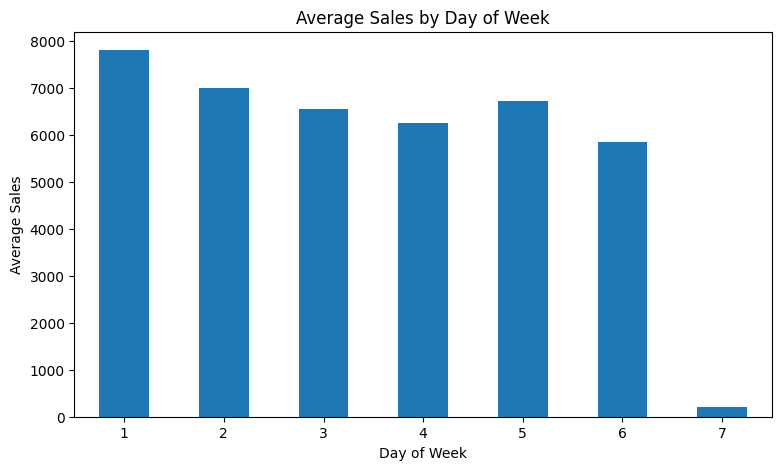

In [24]:
sales_day = train.groupby('DayOfWeek')['Sales'].mean()

plt.figure(figsize=(9, 5))
sales_day.plot(kind='bar')

plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)

plt.show()

In [25]:
train.groupby('Promo')['Sales'].mean()

Promo
0    4406.050805
1    7991.152046
Name: Sales, dtype: float64

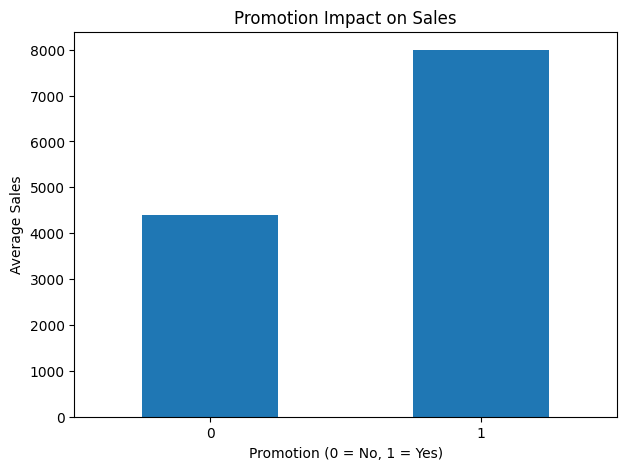

In [26]:
promo_sales = train.groupby('Promo')['Sales'].mean()

promo_sales.plot(kind='bar', figsize=(7, 5))

plt.title("Promotion Impact on Sales")
plt.xlabel("Promotion (0 = No, 1 = Yes)")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)
plt.show()

In [27]:
train.groupby('Promo')['Customers'].mean()

Promo
0    517.823542
1    820.098815
Name: Customers, dtype: float64

In [28]:
train.groupby('StateHoliday')['Sales'].mean()

StateHoliday
0    5947.483893
a     290.735686
b     214.311510
c     168.733171
Name: Sales, dtype: float64

In [29]:
train.groupby('StateHoliday')['Open'].mean()*100

StateHoliday
0    85.532049
a     3.425469
b     2.167414
c     1.731707
Name: Open, dtype: float64

In [30]:
train['Year'] = train['Date'].dt.year
train['Month'] = train['Date'].dt.month
train['Day'] = train['Date'].dt.day
train['WeekOfYear'] = train['Date'].dt.isocalendar().week
train['IsWeekend'] = train['DayOfWeek'].isin([6, 7]).astype(int)

In [31]:
train[['Date', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsWeekend']].head()

,Date,Year,Month,Day,WeekOfYear,IsWeekend
0,2015-07-31,2015,7,31,31,0
1,2015-07-31,2015,7,31,31,0
2,2015-07-31,2015,7,31,31,0
3,2015-07-31,2015,7,31,31,0
4,2015-07-31,2015,7,31,31,0


In [32]:
train = train.merge(store, on='Store', how='left')

In [33]:
print(train.shape)
train.head()

(1017209, 23)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,Year,...,IsWeekend,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,2015,...,0,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,2015,...,0,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,2015,...,0,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,2015,...,0,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,2015,...,0,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [34]:
print("Rows and columns:", train.shape)

print("Missing values:")
print(train.isnull().sum())

Rows and columns: (1017209, 23)
Missing values:


Store                             0
DayOfWeek                         0
Date                              0
Sales                             0
Customers                         0
Open                              0
Promo                             0
StateHoliday                      0
SchoolHoliday                     0
Year                              0
Month                             0
Day                               0
WeekOfYear                        0
IsWeekend                         0
StoreType                         0
Assortment                        0
CompetitionDistance            2642
CompetitionOpenSinceMonth    323348
CompetitionOpenSinceYear     323348
Promo2                            0
Promo2SinceWeek              508031
Promo2SinceYear              508031
PromoInterval                508031
dtype: int64


In [35]:
train['Promo2'].value_counts()

Promo2
1    509178
0    508031
Name: count, dtype: int64

In [36]:
df = train.copy()

df.loc[df['Promo2'] == 0, 'Promo2SinceWeek'] = 0
df.loc[df['Promo2'] == 0, 'Promo2SinceYear'] = 0
df.loc[df['Promo2'] == 0, 'PromoInterval'] = 'No_Promo'

In [37]:
df[['Promo2', 'Promo2SinceWeek',
    'Promo2SinceYear', 'PromoInterval']].isnull().sum()

Promo2             0
Promo2SinceWeek    0
Promo2SinceYear    0
PromoInterval      0
dtype: int64

In [38]:
model_df = df[(df['Open'] == 1) & (df['Sales'] > 0)].copy()
model_df = model_df.sort_values('Date').reset_index(drop=True)
model_df['WeekOfYear'] = model_df['WeekOfYear'].astype(int)

features = ['Store', 'DayOfWeek', 'Promo', 'SchoolHoliday', 'Year', 'Month', 'Day',
            'WeekOfYear', 'IsWeekend', 'StoreType', 'Assortment',
            'CompetitionDistance', 'Promo2']

cutoff = model_df['Date'].max() - pd.Timedelta(weeks=6)
train_df = model_df[model_df['Date'] <= cutoff].copy()
test_df = model_df[model_df['Date'] > cutoff].copy()

print("Train:", train_df.shape, train_df['Date'].min().date(), "to", train_df['Date'].max().date())
print("Test: ", test_df.shape, test_df['Date'].min().date(), "to", test_df['Date'].max().date())

Train: (804056, 23) 2013-01-01 to 2015-06-19
Test:  (40282, 23) 2015-06-20 to 2015-07-31


In [39]:
# Fill missing values using the TRAIN median only
median_dist = train_df['CompetitionDistance'].median()
for d in (train_df, test_df):
    d['CompetitionDistance'] = d['CompetitionDistance'].fillna(median_dist)

X_train = pd.get_dummies(train_df[features], columns=['StoreType', 'Assortment'], dtype=int)
X_test = pd.get_dummies(test_df[features], columns=['StoreType', 'Assortment'], dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

y_train = train_df['Sales']
y_test = test_df['Sales']

def rmspe(y, p):
    return np.sqrt(np.mean(((y - p) / y) ** 2))

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Missing values:", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

Training features: (804056, 18)
Testing features: (40282, 18)
Missing values: 0 0


In [40]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [41]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Make predictions
y_pred = rf_model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
------------------------
MAE: 1232.8738687915763
RMSE: 1738.5846447670185
R2 Score: 0.6760621744104738


In [42]:
comparison = pd.DataFrame({
    'Actual Sales': y_test.iloc[:10].values,
    'Predicted Sales': y_pred[:10]
})

print(comparison)

   Actual Sales  Predicted Sales
0          7654      6246.685683
1          5798      6751.641324
2          8681      6780.918328
3          5123      6747.834220
4          4165      3986.614567
5          3833      4730.844785
6          6469      5430.707593
7          6224      6399.377801
8          3178      6073.040712
9         13820     11931.846901


In [43]:
importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance)

                Feature  Importance
9   CompetitionDistance    0.264098
0                 Store    0.231226
2                 Promo    0.200471
1             DayOfWeek    0.067211
12          StoreType_b    0.037294
7            WeekOfYear    0.035830
10               Promo2    0.033497
6                   Day    0.028079
17         Assortment_c    0.017653
11          StoreType_a    0.015144
5                 Month    0.013482
13          StoreType_c    0.013358
15         Assortment_a    0.013070
14          StoreType_d    0.010490
4                  Year    0.007124
3         SchoolHoliday    0.005634
8             IsWeekend    0.005238
16         Assortment_b    0.001102


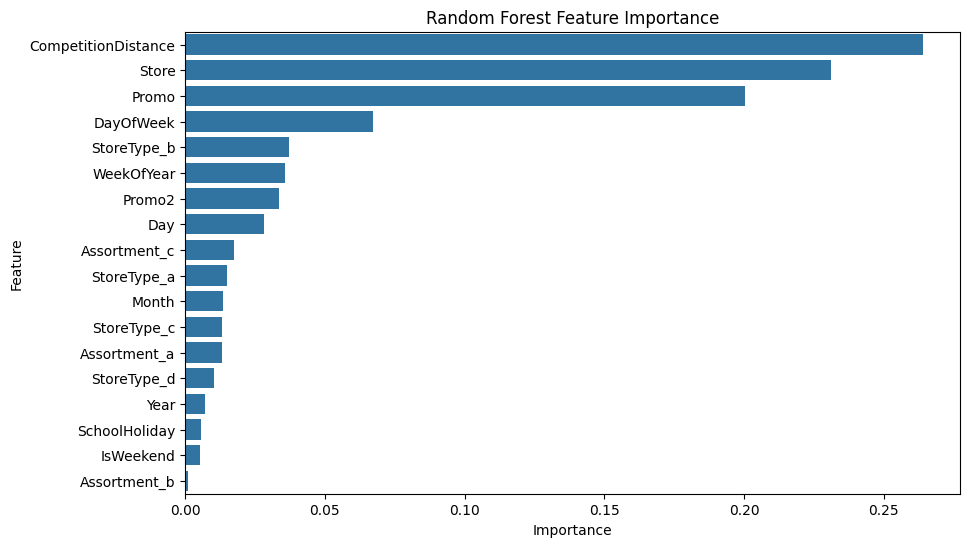

In [44]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.show()

In [45]:
baseline_pred = np.full(len(y_test), y_train.mean())

baseline_mae = mean_absolute_error(y_test, baseline_pred)

print("Baseline MAE:", baseline_mae)
print("Random Forest MAE:", mae)

Baseline MAE: 2252.960198329522
Random Forest MAE: 1232.8738687915763


In [47]:
from xgboost import XGBRegressor

# Create XGBoost model
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

# Train model
xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [48]:
# Make predictions
xgb_pred = xgb_model.predict(X_test)

# Calculate metrics
xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))
xgb_r2 = r2_score(y_test, xgb_pred)

print("XGBoost Evaluation Results")
print("-------------------------")
print("MAE:", xgb_mae)
print("RMSE:", xgb_rmse)
print("R2 Score:", xgb_r2)

XGBoost Evaluation Results
-------------------------
MAE: 944.68310546875
RMSE: 1300.801723937972
R2 Score: 0.8186606168746948


In [49]:
results = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'MAE': [mae, xgb_mae],
    'RMSE': [rmse, xgb_rmse],
    'R2 Score': [r2, xgb_r2],
    'RMSPE': [rmspe(y_test, y_pred), rmspe(y_test, xgb_pred)]
})
results

,Model,MAE,RMSE,R2 Score,RMSPE
0,Random Forest,1232.873869,1738.584645,0.676062,0.284703
1,XGBoost,944.683105,1300.801724,0.818661,0.225608


In [50]:
store_stats = train_df.groupby('Store')['Sales'].agg(Store_mean='mean', Store_median='median', Store_std='std').reset_index()
store_dow = train_df.groupby(['Store', 'DayOfWeek'])['Sales'].mean().rename('Store_DOW_mean').reset_index()
store_promo = train_df.groupby(['Store', 'Promo'])['Sales'].mean().rename('Store_Promo_mean').reset_index()

ly = model_df[['Store', 'Date', 'Sales']].copy()
ly['Date'] = ly['Date'] + pd.Timedelta(days=364)
ly = ly.rename(columns={'Sales': 'Sales_LY'})

def add_feats(d):
    d = d.merge(store_stats, on='Store', how='left')
    d = d.merge(store_dow, on=['Store', 'DayOfWeek'], how='left')
    d = d.merge(store_promo, on=['Store', 'Promo'], how='left')
    d = d.merge(ly, on=['Store', 'Date'], how='left')
    d['StateHoliday_flag'] = (d['StateHoliday'].astype(str) != '0').astype(int)
    return d

train_f = add_feats(train_df)
test_f = add_feats(test_df)

new_feats = ['Store_mean', 'Store_median', 'Store_std', 'Store_DOW_mean',
             'Store_Promo_mean', 'Sales_LY', 'StateHoliday_flag']
all_feats = features + new_feats

X_train2 = pd.get_dummies(train_f[all_feats], columns=['StoreType', 'Assortment'], dtype=int)
X_test2 = pd.get_dummies(test_f[all_feats], columns=['StoreType', 'Assortment'], dtype=int)
X_test2 = X_test2.reindex(columns=X_train2.columns, fill_value=0)
print(X_train2.shape, X_test2.shape)

(804056, 25) (40282, 25)


In [51]:
xgb2 = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=8,
                    subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1)
xgb2.fit(X_train2, np.log1p(train_f['Sales']))
pred2 = np.expm1(xgb2.predict(X_test2))
print("done")

done


In [52]:
y_test2 = test_f['Sales']
print("MAE  :", mean_absolute_error(y_test2, pred2))
print("RMSE :", np.sqrt(mean_squared_error(y_test2, pred2)))
print("R2   :", r2_score(y_test2, pred2))
print("RMSPE:", rmspe(y_test2, pred2))

MAE  : 646.970947265625
RMSE : 945.7417393242196
R2   : 0.9041449427604675
RMSPE: 0.1356155438642623


In [53]:
import joblib, os

os.makedirs("../models", exist_ok=True)
joblib.dump(xgb2, "../models/xgb2.joblib")
joblib.dump(list(X_train2.columns), "../models/feature_columns.joblib")
test_f.assign(Predicted=pred2).to_parquet("../data/test_predictions.parquet")
print("saved")

saved
